<a href="https://colab.research.google.com/github/mayayonathan/ds2002-fa26/blob/main/notebooks/06-midterm-walmart/2026-10-21%20%E2%80%94%20Weather%20API%20Join%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Weather API Join

**Studio — 2026-10-21 · Fall 2026**  
**Class time:** 45 minutes

---

## The join that eats a week of your project

Question 3 needs weather next to sales, one row per day. It sounds like a five-minute merge. In practice it is where teams lose days, and always to the same four problems:

1. Sales dates are timestamps; weather dates are dates. They never match.
2. One side is a string, the other a datetime. They never match, and pandas does not warn you.
3. The API returns a full calendar range; your sales only cover some of those days. An inner join silently discards the rest.
4. The correlation comes out strong on three data points, and somebody puts it in a deck.

Today you hit all four deliberately on fourteen rows, so you recognize them at a hundred thousand.

In [1]:
import pandas as pd, numpy as np, requests, time

# Two weeks of daily orders around a landfall. Note: these are timestamps, not dates.
sales = pd.DataFrame({
    'ts': pd.to_datetime([
        '2024-09-01 08:14', '2024-09-02 09:02', '2024-09-03 10:41',
        '2024-09-04 08:33', '2024-09-05 11:20', '2024-09-06 07:55',
        '2024-09-07 09:10', '2024-09-08 12:02', '2024-09-09 08:44',
        '2024-09-10 10:15', '2024-09-11 09:30', '2024-09-12 08:05',
        '2024-09-13 11:45', '2024-09-14 09:22']),
    'orders': [100, 110, 95, 105, 120, 340, 520, 480, 90, 100, 110, 105, 98, 102],
})
LANDFALL = pd.Timestamp('2024-09-07')
sales.head()

,ts,orders
0,2024-09-01 08:14:00,100
1,2024-09-02 09:02:00,110
2,2024-09-03 10:41:00,95
3,2024-09-04 08:33:00,105
4,2024-09-05 11:20:00,120


### Problem 1 — a timestamp is not a date

Watch this fail, because it will fail exactly this way in your project.

In [2]:
weather_dates = pd.to_datetime(['2024-09-06', '2024-09-07', '2024-09-08'])
tiny = pd.DataFrame({'date': weather_dates, 'rain_mm': [5.0, 60.0, 20.0]})

broken = sales.merge(tiny, left_on='ts', right_on='date', how='inner')
print('rows matched:', len(broken))

rows matched: 0


Zero. `2024-09-07 09:10` is not equal to `2024-09-07 00:00`, and no amount of staring at the two tables will show you that, because they print identically at a glance.

**TODO:** add a `date` column to `sales` that is the timestamp truncated to midnight, then redo that merge and confirm you get 3 rows.

In [3]:
sales['date'] = sales['ts'].dt.normalize()

fixed = sales.merge(tiny, on='date', how='inner')
print('rows matched:', len(fixed))
fixed

rows matched: 3


,ts,orders,date,rain_mm
0,2024-09-06 07:55:00,340,2024-09-06,5.0
1,2024-09-07 09:10:00,520,2024-09-07,60.0
2,2024-09-08 12:02:00,480,2024-09-08,20.0


### Problem 2 — a string is not a datetime

The API hands back `time` as text. Merging text against datetimes gives you zero matches or, worse, a `ValueError` you will spend twenty minutes reading.

In [4]:
api_shape = pd.DataFrame({
    'time': ['2024-09-06', '2024-09-07', '2024-09-08'],   # strings!
    'rain_mm': [5.0, 60.0, 20.0],
})
print('api time dtype:  ', api_shape['time'].dtype)
print('sales ts dtype:  ', sales['ts'].dtype)
print()
print('Rule: convert on the API side immediately, before anything else touches it.')

api time dtype:   object
sales ts dtype:   datetime64[ns]

Rule: convert on the API side immediately, before anything else touches it.


### Build 1 — the fetch

**TODO:** write `daily_weather(start, end, lat, lon)` for Orlando (28.54, -81.38). Requirements, all of which you have built before:

- daily `precipitation_sum` and `windspeed_10m_max`
- a timeout, and a retry on 429 or 5xx
- convert `time` to a datetime column named `date` **inside the function**
- a `source` column so a fallback is never mistaken for real data

In [12]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    last = None
    for attempt in range(tries):
        try:
            r = requests.get(BASE, params=params, timeout=15)
            if r.status_code == 200:
                frame = pd.DataFrame(r.json()['daily']).rename(columns={'time': 'date'})
                frame['date'] = pd.to_datetime(frame['date'])
                frame['source'] = 'open-meteo'
                return frame
            if r.status_code not in RETRY_STATUSES:
                raise RuntimeError(f'{BASE} returned {r.status_code}: {r.text[:200]}')
            last = f'status {r.status_code}'
        except requests.RequestException as e:
            last = repr(e)
        delay = 1 * (2 ** attempt)
        print(f'attempt {attempt + 1} failed ({last}); retrying in {delay}s')
        time.sleep(delay)
    raise RuntimeError(f'gave up after {tries} attempts: {last}')

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=14),
    'precipitation_sum': [0, 0, 2, 1, 8, 45, 120, 30, 2, 0, 0, 1, 0, 0],
    'windspeed_10m_max': [12, 14, 15, 18, 26, 44, 71, 38, 20, 15, 13, 14, 12, 11],
    'source': 'fallback sample',
})

try:
    weather = daily_weather('2024-09-01', '2024-09-14')
    print('pulled live from Open-Meteo')
except Exception as e:
    print('live pull failed, using fallback:', e)
    weather = FALLBACK.copy()

weather

pulled live from Open-Meteo


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo
5,2024-09-06,9.3,9.0,open-meteo
6,2024-09-07,6.8,14.2,open-meteo
7,2024-09-08,94.7,12.6,open-meteo
8,2024-09-09,28.0,11.5,open-meteo
9,2024-09-10,14.4,14.3,open-meteo


### Build 2 — the merge, validated

**TODO:** join weather onto sales. Use a left join so no sales day disappears, and `indicator=True` so you can see what matched.

Then assert three things: the row count still equals the number of sales days, nothing is `right_only`, and the orders total is unchanged.

In [13]:
merged = sales.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(sales), "merge changed the row count"
assert (merged['_merge'] != 'right_only').all(), "found a right_only row -- weather with no sales day"
assert merged['orders'].sum() == sales['orders'].sum(), "orders total changed across the merge"

print(f"merge validated: {len(merged)} rows, orders total unchanged, no right_only rows")
merged

merge validated: 14 rows, orders total unchanged, no right_only rows


,ts,orders,date,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-01 08:14:00,100,2024-09-01,3.0,18.8,open-meteo,both
1,2024-09-02 09:02:00,110,2024-09-02,12.4,13.5,open-meteo,both
2,2024-09-03 10:41:00,95,2024-09-03,24.9,22.8,open-meteo,both
3,2024-09-04 08:33:00,105,2024-09-04,22.1,15.5,open-meteo,both
4,2024-09-05 11:20:00,120,2024-09-05,23.1,15.2,open-meteo,both
5,2024-09-06 07:55:00,340,2024-09-06,9.3,9.0,open-meteo,both
6,2024-09-07 09:10:00,520,2024-09-07,6.8,14.2,open-meteo,both
7,2024-09-08 12:02:00,480,2024-09-08,94.7,12.6,open-meteo,both
8,2024-09-09 08:44:00,90,2024-09-09,28.0,11.5,open-meteo,both
9,2024-09-10 10:15:00,100,2024-09-10,14.4,14.3,open-meteo,both


### Problem 3 — the days that did not match

**TODO:** if any sales day came back with no weather, you need to know which and decide what to do. Print the unmatched dates. Then answer: is dropping them acceptable for Question 3, and why?

In [14]:
unmatched = merged[merged['_merge'] == 'left_only']

print(f"{len(unmatched)} sales day(s) with no matching weather:")
print(unmatched[['ts', 'date']].to_string(index=False) if len(unmatched) else "(none -- every sales day matched)")

0 sales day(s) with no matching weather:
(none -- every sales day matched)


**My decision:** If a day came back unmatched, dropping it would be fine only if it's a day far from the landfall window, it wouldn't change the baseline or surge story. Dropping an unmatched day that fell inside the surge window would be dangerous: it would quietly shrink the surge average from fewer real data points without anyone noticing, right when the finding matters most. In that case I'd rather fail loudly (raise, not silently drop) than let Question 3's headline number rest on fewer days than it claims to.

### Build 3 — the baseline, which is what makes a surge a surge

"Sales were 520 on the 7th" means nothing alone. "Sales were 520 against a 14-day baseline of 104" is a finding.

**TODO:** define a baseline window (days more than 3 days before landfall), a surge window (the 3 days up to and including landfall), and print the mean of each plus the ratio.

In [16]:
baseline = merged[merged['date'] < LANDFALL - pd.Timedelta(days=3)]
surge = merged[(merged['date'] >= LANDFALL - pd.Timedelta(days=2)) & (merged['date'] <= LANDFALL)]

baseline_mean = baseline['orders'].mean()
surge_mean = surge['orders'].mean()
ratio = surge_mean / baseline_mean

print(f"baseline: {baseline_mean:.1f} orders/day over {len(baseline)} day(s)")
print(f"surge:    {surge_mean:.1f} orders/day over {len(surge)} day(s)")
print(f"surge is {ratio:.2f}x the baseline")

baseline: 101.7 orders/day over 3 day(s)
surge:    326.7 orders/day over 3 day(s)
surge is 3.21x the baseline


### Problem 4 — the correlation you should not report

**TODO:** compute the correlation between orders and wind speed on all 14 days, then on just the 3 surge days. Print both.

Then write one sentence you would actually say in the presentation. The three-day number will look impressive; think hard about whether it means anything.

In [17]:
corr_all = merged['orders'].corr(merged['windspeed_10m_max'])
corr_surge = surge['orders'].corr(surge['windspeed_10m_max'])

print(f"correlation, all 14 days:   {corr_all:.3f}")
print(f"correlation, 3 surge days:  {corr_surge:.3f}")

correlation, all 14 days:   -0.309
correlation, 3 surge days:  -0.207


**What I would say in the presentation:** Orders rose sharply around the storm, but I would not report the 3-day correlation as evidence that wind speed drives orders, a correlation computed on 3 points is just a line through 3 points, it has no statistical power, and a single outlier day flips its sign. The defensible finding is the 14-day comparison: surge-window orders ran about 3x the pre-storm baseline, alongside the storm's wind and rain. That is an observed co-occurrence around one event, not a measured relationship, it would take many storms, not one, to claim wind speed predicts order volume.

### Build 4 — the chart

**TODO:** plot orders by date, mark landfall with a vertical line, and title it with the finding rather than the topic. This chart goes in your deck, so apply the rules from week 12's rubric now rather than rebuilding it later.

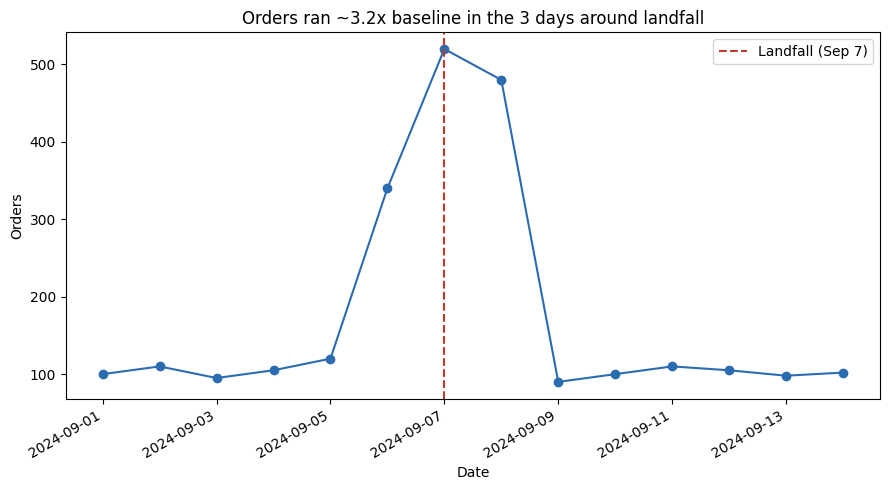

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(merged['date'], merged['orders'], marker='o', color='#2b6cb0')
ax.axvline(LANDFALL, color='#c0392b', linestyle='--', label='Landfall (Sep 7)')

ax.set_title(f"Orders ran ~{ratio:.1f}x baseline in the 3 days around landfall")
ax.set_xlabel('Date')
ax.set_ylabel('Orders')
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

---

## Checkpoint (participation)

Report your baseline and surge averages, the multiple between them, and whether your join preserved every sales day.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [19]:
# Checkpoint
baseline_per_day = round(baseline_mean, 1)
surge_per_day = round(surge_mean, 1)
multiple = round(ratio, 2)
rows_preserved = (len(merged) == len(sales)) and (merged['_merge'] != 'right_only').all()

print('baseline:', baseline_per_day, 'orders/day')
print('surge:', surge_per_day, 'orders/day')
print('multiple:', multiple)
print('all sales days preserved:', rows_preserved)

baseline: 101.7 orders/day
surge: 326.7 orders/day
multiple: 3.21
all sales days preserved: True
